<center><h1>Guo_Haosen_HW6</h1></center>

Name: Haosen Guo
<br>
Github Username: iamevan-g
<br>
USC ID: 7183115772

## 1. Tree-Based Methods

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
import xgboost as xgb
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.preprocessing import StandardScaler

### (a) Download the APS Failure data

In [2]:
DATA_DIR = "../data"

# First 20 lines are license text; missing values are encoded as "na"
train_df = pd.read_csv(f"{DATA_DIR}/aps_failure_training_set.csv", skiprows=20, na_values="na")
test_df = pd.read_csv(f"{DATA_DIR}/aps_failure_test_set.csv", skiprows=20, na_values="na")

print(train_df.shape, test_df.shape)
train_df.head()

(60000, 171) (16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Common ways to deal with missing values include deleting rows or columns with missing data, filling them with a simple statistic like the mean, median, or mode, KNN imputation, and model-based methods such as iterative (MICE) imputation. Since almost every row in this dataset has at least one missing value, deleting them isn't really an option. I'll go with median imputation because it's simple and less sensitive to the skewed values and outliers in this data. Following the footnote, I'll fill the test set using its own medians.

#### (ii) Calculate the coefficient of variation

In [3]:
X_train = train_df.drop(columns="class")
y_train = (train_df["class"] == "pos").astype(int)
X_test = test_df.drop(columns="class")
y_test = (test_df["class"] == "pos").astype(int)

# Median imputation, test set uses its own statistics
X_train = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X_train), columns=X_train.columns)
X_test = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X_test), columns=X_test.columns)

cv = (X_train.std() / X_train.mean()).sort_values(ascending=False)
cv.to_frame("CV")

,CV
cf_000,244.887517
co_000,244.507385
ad_000,244.322816
cs_009,237.930554
dh_000,123.216097
...,...
bo_000,0.792383
bp_000,0.753392
bq_000,0.718534
br_000,0.689112


#### (iii) Plot a correlation matrix

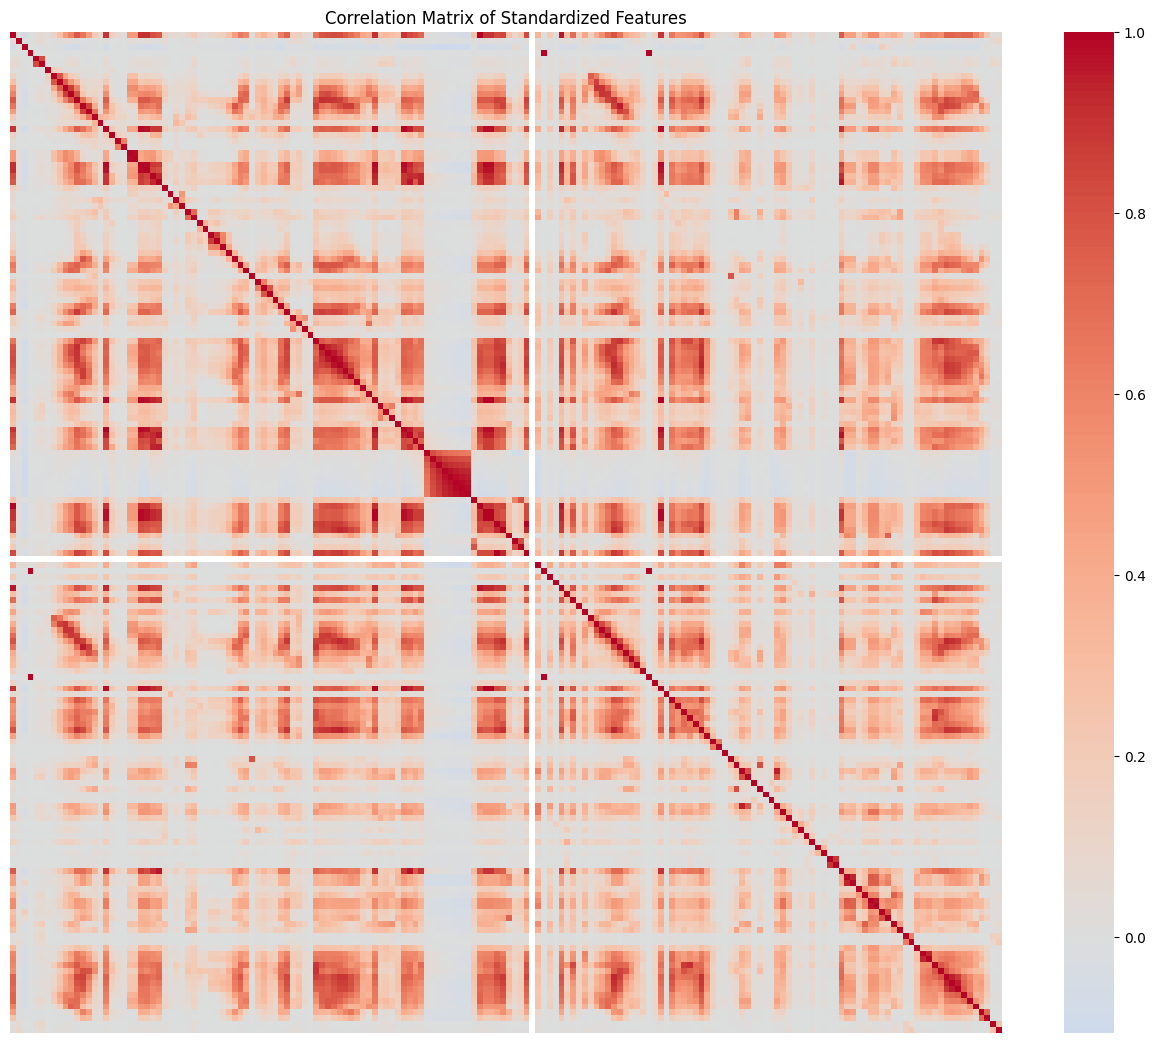

In [4]:
X_std = pd.DataFrame(StandardScaler().fit_transform(X_train), columns=X_train.columns)

plt.figure(figsize=(16, 13))
sns.heatmap(X_std.corr(), cmap="coolwarm", center=0, xticklabels=False, yticklabels=False)
plt.title("Correlation Matrix of Standardized Features")
plt.show()

#### (iv) Make scatter plots and box plots

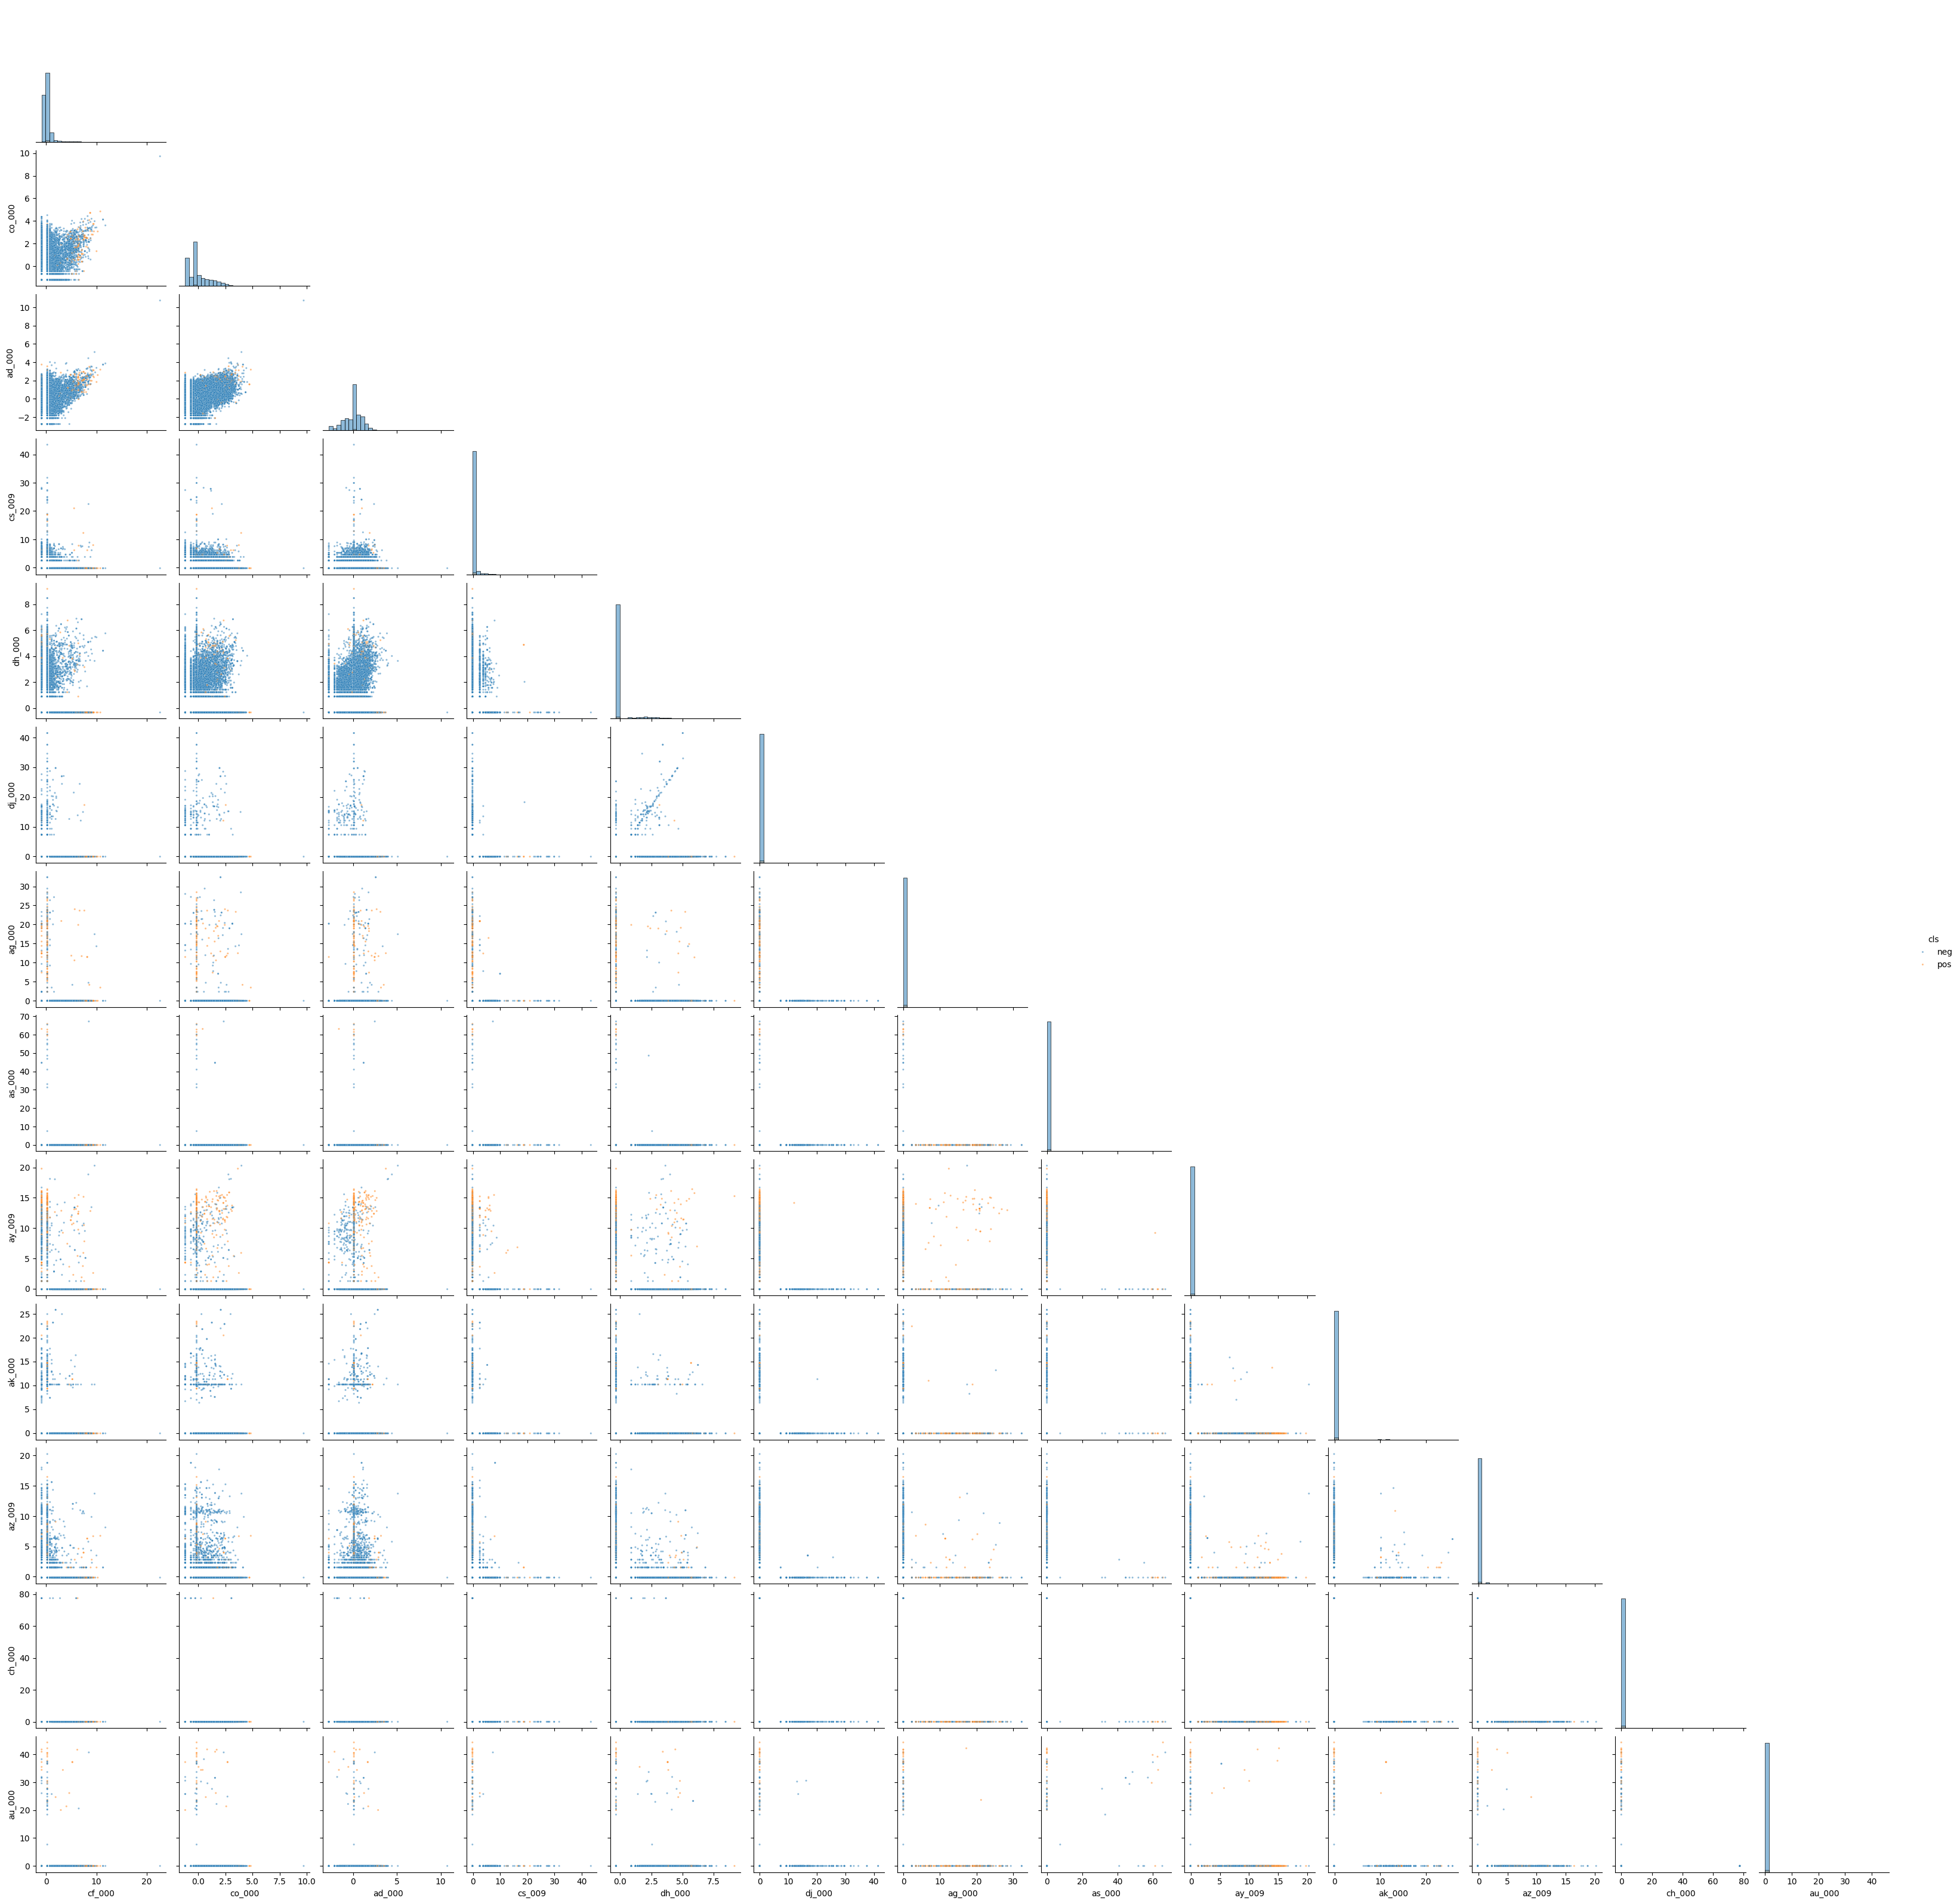

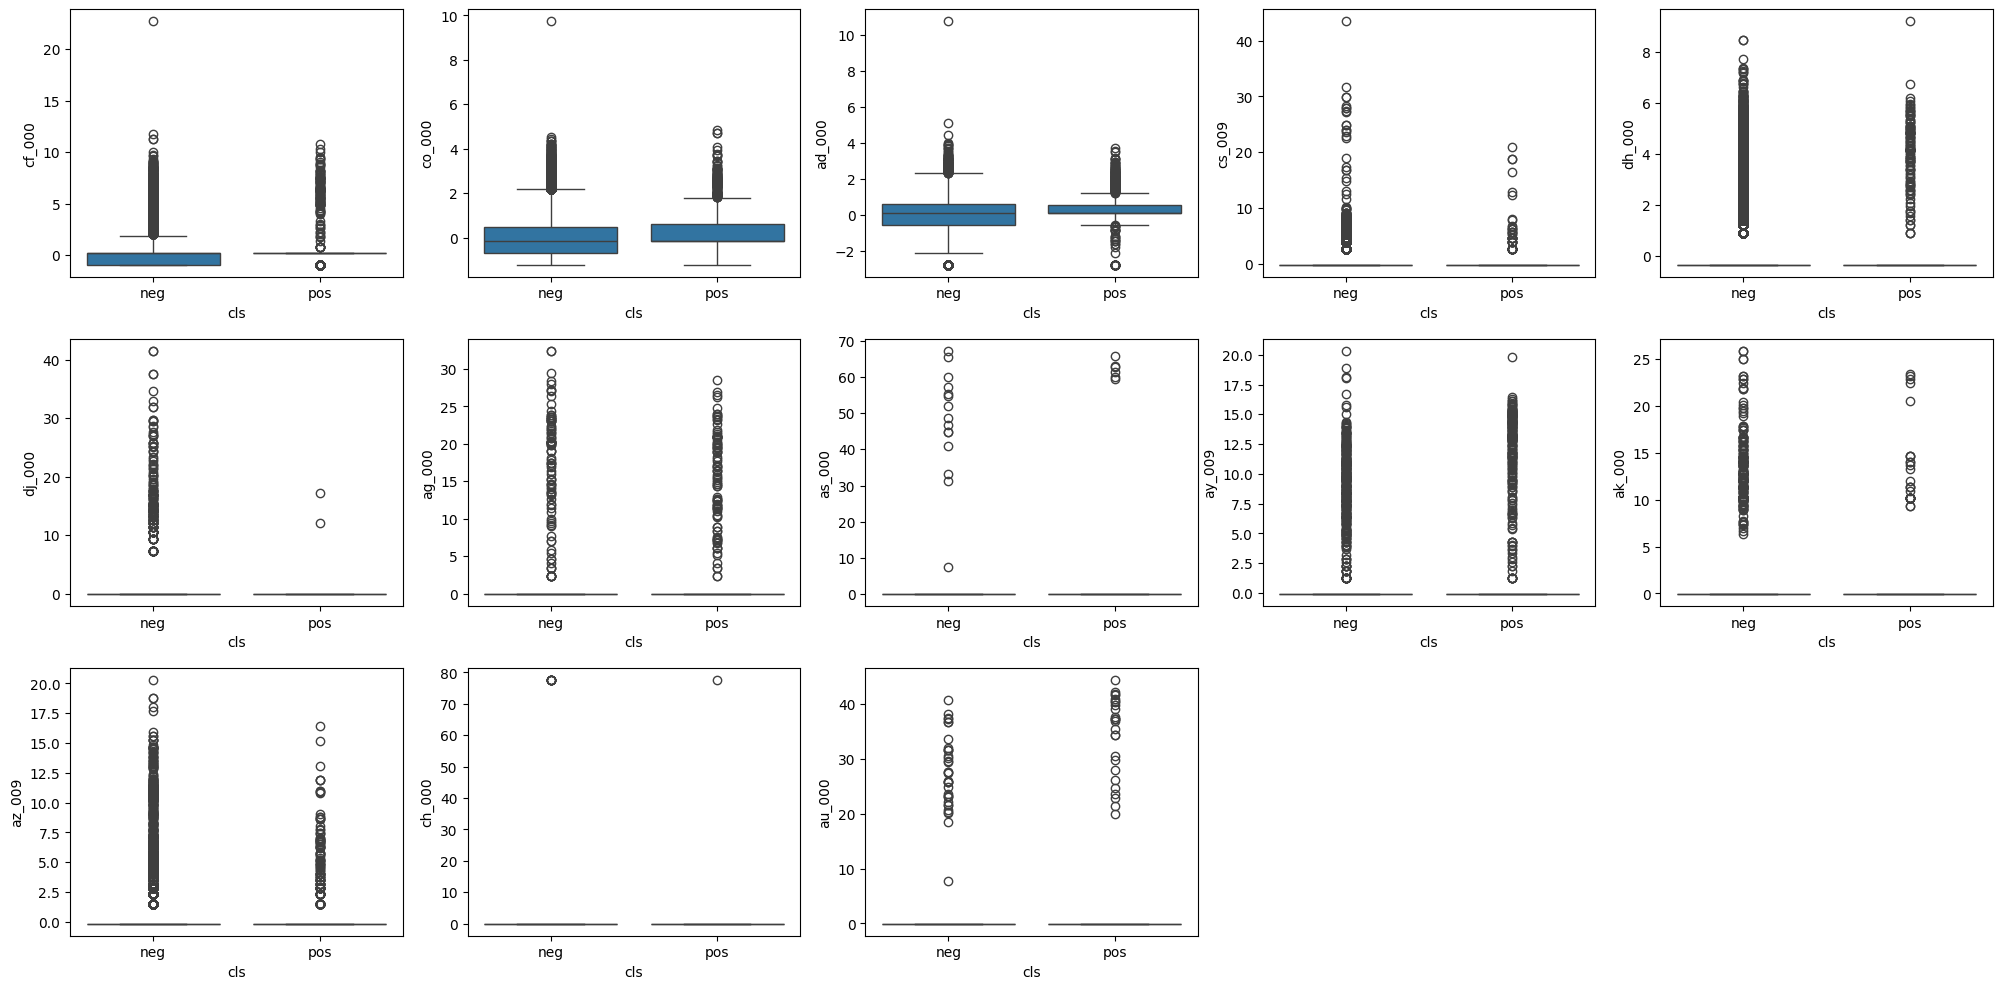

In [5]:
top = cv.index[:int(np.sqrt(170))]

# log1p first (features are extremely skewed), then standardize
X_top = pd.DataFrame(StandardScaler().fit_transform(np.log1p(X_train[top])), columns=top)
plot_df = X_top.assign(cls=train_df["class"])

sns.pairplot(plot_df, hue="cls", hue_order=["neg", "pos"], corner=True, diag_kind="hist",
             plot_kws={"s": 5, "alpha": 0.5}, diag_kws={"bins": 30})
plt.show()

fig, axes = plt.subplots(3, 5, figsize=(20, 10))
for ax, col in zip(axes.flat, top):
    sns.boxplot(data=plot_df, x="cls", y=col, order=["neg", "pos"], ax=ax)
for ax in axes.flat[len(top):]:
    ax.remove()
plt.tight_layout()
plt.show()

Not really. Most of these features are zero for the vast majority of trucks, so the points pile up on the axes and the two classes overlap a lot. The vertical bands in some plots are also just imputed medians, since positive trucks have many more missing values. On top of that, there are only 1,000 positives against 59,000 negatives, which makes visual comparison unreliable. Some features like ay_009, ag_000 and au_000 do seem to take larger values more often for the positive class, which hints they might be useful, but scatter plots alone can't tell us whether a feature is actually significant. We'd need a model or a statistical test for that.

#### (v) Is this data set imbalanced?

In [6]:
counts = pd.DataFrame({
    "train": train_df["class"].value_counts(),
    "test": test_df["class"].value_counts(),
})
print(counts)
print()
print("Positive ratio:")
print((counts.loc["pos"] / counts.sum()).round(4))


       train   test
class              
neg    59000  15625
pos     1000    375

Positive ratio:
train    0.0167
test     0.0234
dtype: float64


The training set has 59,000 negative and 1,000 positive samples, and the test set has 15,625 negative and 375 positive samples. Positives make up only about 1.7% and 2.3% of the data, so the data set is highly imbalanced. A classifier that always predicts negative would already reach over 97% accuracy, so accuracy alone is not a meaningful metric here.

### (c) Train a random forest

--- Train ---
[[59000     0]
 [    1   999]]
AUC: 1.0000, Misclassification: 0.00002
--- Test ---
[[15610    15]
 [  106   269]]
AUC: 0.9928, Misclassification: 0.00756


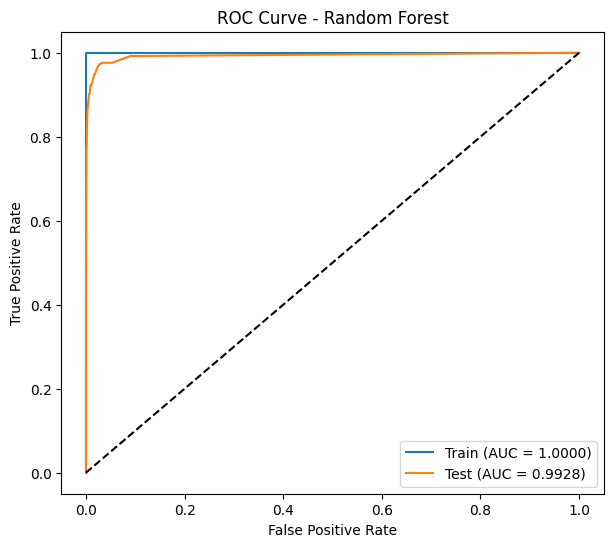

OOB error: 0.0062, Test error: 0.0076


In [7]:
def evaluate(model, X, y, name):
    y_pred = model.predict(X)
    y_prob = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, y_prob)
    auc = roc_auc_score(y, y_prob)
    err = 1 - accuracy_score(y, y_pred)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")
    print(f"--- {name} ---")
    print(confusion_matrix(y, y_pred))
    print(f"AUC: {auc:.4f}, Misclassification: {err:.5f}")
    return err

rf = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

plt.figure(figsize=(7, 6))
evaluate(rf, X_train, y_train, "Train")
test_err = evaluate(rf, X_test, y_test, "Test")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.show()

print(f"OOB error: {1 - rf.oob_score_:.4f}, Test error: {test_err:.4f}")

The random forest fits the training data almost perfectly (only 1 error, AUC = 1.0), which is expected since fully grown trees basically memorize the training set. On the test set the misclassification rate is 0.76% and AUC is 0.993, so it looks really good on paper. But the confusion matrix tells a different story: 106 of the 375 positive trucks are missed, so recall on the positive class is only about 72%. The low error mostly comes from getting the huge negative class right, which is the effect of the class imbalance.

The OOB error is 0.62%, pretty close to the test error of 0.76%, so OOB gives a reasonable estimate of the test error without needing a separate validation set. It's slightly optimistic, partly because the test set has a bit higher proportion of positives (2.3% vs 1.7%).

### (d) Research class imbalance in random forest

d:\anaconda3\Lib\site-packages\imblearn\ensemble\_forest.py:887: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


--- Train ---
[[55762  3238]
 [    0  1000]]
AUC: 0.9972, Misclassification: 0.05397
--- Test ---
[[14789   836]
 [    6   369]]
AUC: 0.9920, Misclassification: 0.05263


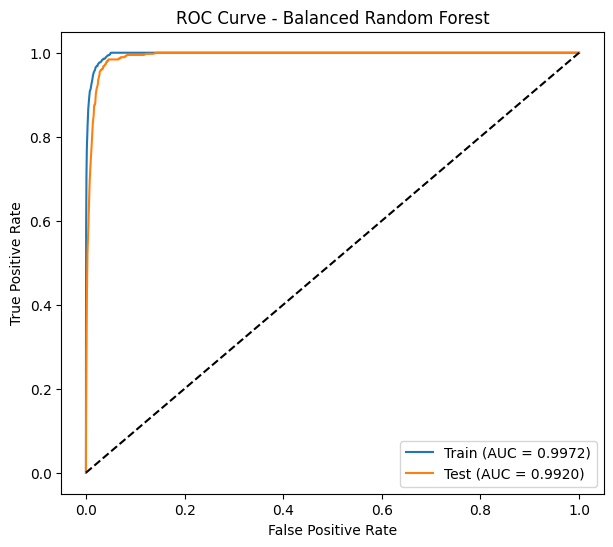

OOB error: 0.0328, Test error: 0.0526


In [8]:
brf = BalancedRandomForestClassifier(n_estimators=100, sampling_strategy="auto", replacement=False,
                                     bootstrap=True, oob_score=True, random_state=42, n_jobs=-1)
brf.fit(X_train, y_train)

plt.figure(figsize=(7, 6))
evaluate(brf, X_train, y_train, "Train")
test_err_brf = evaluate(brf, X_test, y_test, "Test")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Balanced Random Forest")
plt.legend()
plt.show()

print(f"OOB error: {1 - brf.oob_score_:.4f}, Test error: {test_err_brf:.4f}")

Class imbalance in random forests is usually handled by class weighting or by a balanced random forest, where each tree is trained on a bootstrap sample with the majority class undersampled. I used a balanced random forest.

Compared to 1c, test misclassification went up (0.76% to 5.26%) and AUC stayed about the same (~0.992), but missed failures dropped from 106 to 6, so positive-class recall went from 72% to 98%, at the cost of more false alarms. Since missing a real failure is much more costly here, the balanced model is better. The OOB error (3.28%) is lower than the test error, because OOB samples are mostly negatives, so it's less reliable than in 1c.

### (e) XGBoost and Model Trees

Best alpha: 0.01, 5-fold CV error: 0.0063
--- Train ---
[[59000     0]
 [    1   999]]
AUC: 1.0000, Misclassification: 0.00002
--- Test ---
[[15609    16]
 [   86   289]]
AUC: 0.9937, Misclassification: 0.00638


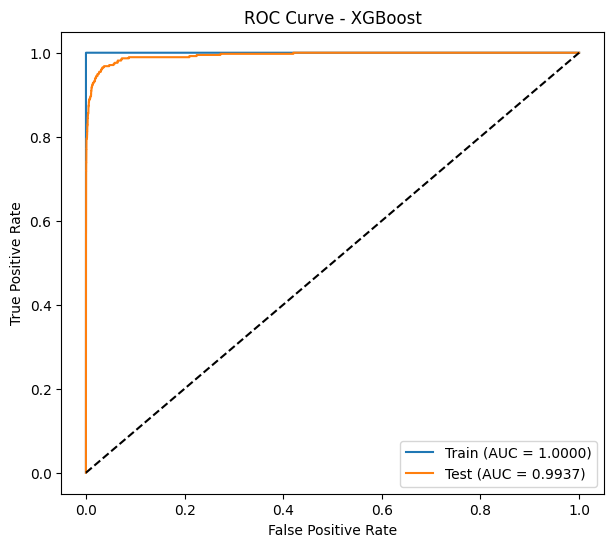

CV error: 0.0063, Test error: 0.0064


In [9]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(xgb.XGBClassifier(objective="binary:logistic", random_state=42, n_jobs=-1),
                    {"reg_alpha": [0, 0.01, 0.1, 1, 10, 100]}, cv=kf, scoring="accuracy")
grid.fit(X_train, y_train)
xgb_model = grid.best_estimator_

print(f"Best alpha: {grid.best_params_['reg_alpha']}, 5-fold CV error: {1 - grid.best_score_:.4f}")

plt.figure(figsize=(7, 6))
evaluate(xgb_model, X_train, y_train, "Train")
test_err_xgb = evaluate(xgb_model, X_test, y_test, "Test")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost")
plt.legend()
plt.show()

print(f"CV error: {1 - grid.best_score_:.4f}, Test error: {test_err_xgb:.4f}")

XGBoost's default trees still split on one feature at a time, so this isn't a true model tree. I used the logistic loss (`binary:logistic`) with an L1 penalty (`reg_alpha`, applied to leaf weights) as the XGBoost version of L1-penalized logistic regression at each node.

I used 5-fold stratified CV to pick α from {0, 0.01, 0.1, 1, 10, 100}, and α = 0.01 gave the lowest CV error. The 5-fold CV error (0.63%) is very close to the test error (0.64%), so CV gives a good estimate, though it's slightly optimistic since the same folds were also used to choose α. The model fits the training set almost perfectly (AUC = 1.0) and gets a test AUC of 0.994. It's a bit better than the random forest in 1c, but since we didn't compensate for imbalance, it still misses 86 of the 375 positive trucks.

### (f) Use SMOTE to pre-process your data

In [10]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pipe = Pipeline([("smote", SMOTE(random_state=42)),
                 ("xgb", xgb.XGBClassifier(objective="binary:logistic", random_state=42, n_jobs=-1))])
grid_smote = GridSearchCV(pipe, {"xgb__reg_alpha": [0, 0.01, 0.1, 1, 10, 100]}, cv=kf, scoring="accuracy")
grid_smote.fit(X_train, y_train)
smote_model = grid_smote.best_estimator_

Best alpha: 1
--- Train ---
[[59000     0]
 [    1   999]]
AUC: 1.0000, Misclassification: 0.00002
--- Test ---
[[15554    71]
 [   56   319]]
AUC: 0.9945, Misclassification: 0.00794


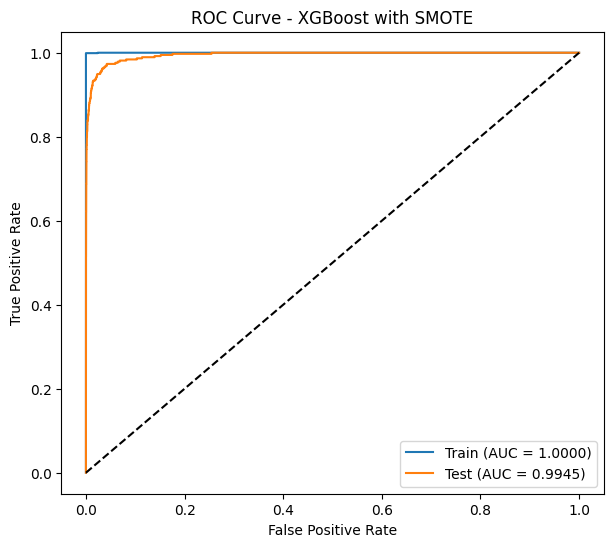

5-fold CV error: 0.0063, Test error: 0.0079


In [11]:
print(f"Best alpha: {grid_smote.best_params_['xgb__reg_alpha']}")

plt.figure(figsize=(7, 6))
evaluate(smote_model, X_train, y_train, "Train")
test_err_smote = evaluate(smote_model, X_test, y_test, "Test")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost with SMOTE")
plt.legend()
plt.show()

print(f"5-fold CV error: {1 - grid_smote.best_score_:.4f}, Test error: {test_err_smote:.4f}")

SMOTE is placed inside a pipeline, so in each CV fold it is only applied to the training part and the validation fold stays original. Applying SMOTE before CV would leak synthetic samples into validation and make the CV error too optimistic.

CV picked α = 1, with a CV error of 0.63% vs. a test error of 0.79%. Compared to 1e, the overall error went up slightly (0.64% to 0.79%) and AUC barely changed, but SMOTE catches more failures: missed positives dropped from 86 to 56 (recall 77% to 85%), at the cost of more false alarms (16 to 71).

## 2. ISLR 6.6.3

(a) iv. Steadily decrease. As s increases, the constraint gets looser and the model becomes more flexible, so it fits the training data better and training RSS keeps going down until it reaches the least squares solution.

(b) ii. Decrease initially, then increase in a U shape. At first, the extra flexibility reduces bias more than it adds variance, so test RSS drops. Once s gets too large, the model starts to overfit and test RSS goes back up.

(c) iii. Steadily increase. At s = 0 the model is just a constant, so variance is zero. As s grows, the coefficients depend more on the training data, so variance keeps increasing.

(d) iv. Steadily decrease. A more flexible model can capture the true relationship better, so squared bias keeps going down.

(e) v. Remain constant. Irreducible error comes from the noise ε, not from the model, so it doesn’t depend on s.

## 3. ISLR 6.6.5

(a) Let $x_{11} = x_{12} = a$, then $x_{21} = x_{22} = -a$ and $y_2 = -y_1$. Since $\beta_0 = 0$, ridge regression minimizes

$$(y_1 - a\beta_1 - a\beta_2)^2 + (y_2 + a\beta_1 + a\beta_2)^2 + \lambda(\beta_1^2 + \beta_2^2)$$

Using $y_2 = -y_1$, this is $2(y_1 - a\beta_1 - a\beta_2)^2 + \lambda(\beta_1^2 + \beta_2^2)$.

(b) Take derivatives and set them to 0:

$$-4a(y_1 - a\beta_1 - a\beta_2) + 2\lambda\beta_1 = 0$$
$$-4a(y_1 - a\beta_1 - a\beta_2) + 2\lambda\beta_2 = 0$$

The first part is the same in both equations, so subtracting them gives $2\lambda(\beta_1 - \beta_2) = 0$, which means $\hat\beta_1 = \hat\beta_2$.

(c) Lasso minimizes

$$2(y_1 - a\beta_1 - a\beta_2)^2 + \lambda(|\beta_1| + |\beta_2|)$$

(d) The RSS part only depends on $\beta_1 + \beta_2$. If $\beta_1$ and $\beta_2$ have the same sign, then $|\beta_1| + |\beta_2| = |\beta_1 + \beta_2|$, so the penalty also only depends on the sum. This means the objective only depends on $\beta_1 + \beta_2$, and once we find the best sum $\hat\beta_1 + \hat\beta_2 = t$, any $\beta_1, \beta_2$ with the same sign that add up to $t$ is a solution. So the solutions are not unique; they form a line segment from $(t, 0)$ to $(0, t)$.

## 4. ISLR 8.4.5

Majority vote: 6 of the 10 estimates are greater than 0.5 (0.55, 0.6, 0.6, 0.65, 0.7, 0.75), so 6 trees vote Red and 4 vote Green. The final classification is Red.

Average probability: $(0.1 + 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75)/10 = 4.5/10 = 0.45 < 0.5$, so the final classification is Green.

## 5. ISLR 9.7.3

### (a)

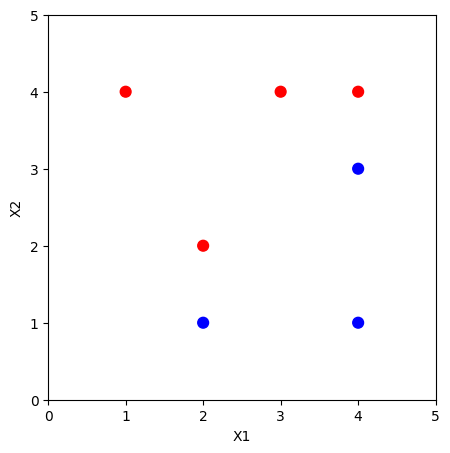

In [12]:
X = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
colors = ["red"] * 4 + ["blue"] * 3
x = np.linspace(0, 5, 100)

def plot_points():
    plt.figure(figsize=(5, 5))
    plt.scatter(X[:, 0], X[:, 1], c=colors, s=60)
    plt.xlim(0, 5)
    plt.ylim(0, 5)
    plt.xlabel("X1")
    plt.ylabel("X2")

plot_points()
plt.show()

### (b)

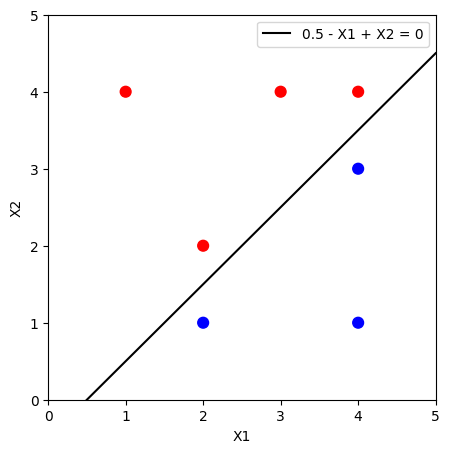

In [13]:
plot_points()
plt.plot(x, x - 0.5, "k-", label="0.5 - X1 + X2 = 0")
plt.legend()
plt.show()

The optimal separating hyperplane passes halfway between the points (2,2), (4,4) and (2,1), (4,3), which gives $X_2 = X_1 - 0.5$, or $0.5 - X_1 + X_2 = 0$.

### (c)
Classify to Red if $0.5 - X_1 + X_2 > 0$, and Blue otherwise. So $\beta_0 = 0.5$, $\beta_1 = -1$, $\beta_2 = 1$.

### (d)

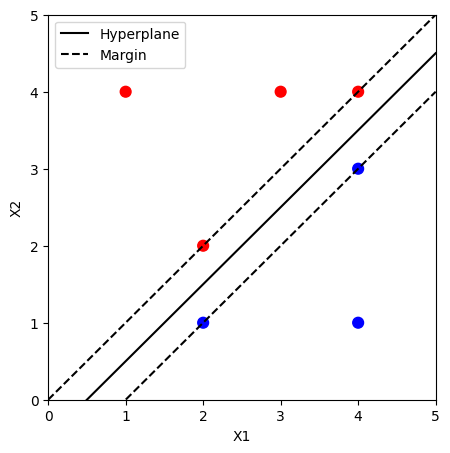

In [14]:
plot_points()
plt.plot(x, x - 0.5, "k-", label="Hyperplane")
plt.plot(x, x, "k--", label="Margin")
plt.plot(x, x - 1, "k--")
plt.legend()
plt.show()

The margin is bounded by the dashed lines $X_2 = X_1$ and $X_2 = X_1 - 1$. The distance from the hyperplane to each margin line is $0.5/\sqrt{2} \approx 0.354$.

### (e)

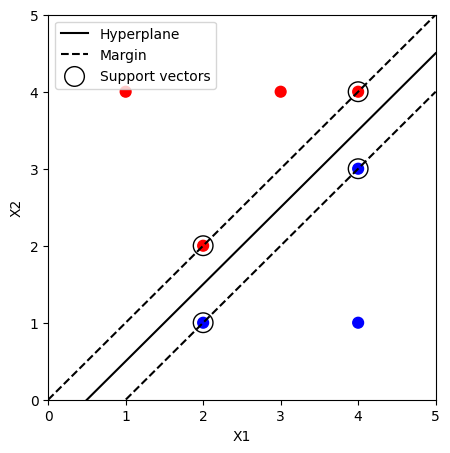

In [15]:
plot_points()
plt.plot(x, x - 0.5, "k-", label="Hyperplane")
plt.plot(x, x, "k--", label="Margin")
plt.plot(x, x - 1, "k--")
sv = X[[1, 2, 4, 5]]
plt.scatter(sv[:, 0], sv[:, 1], s=200, facecolors="none", edgecolors="k", label="Support vectors")
plt.legend()
plt.show()

The support vectors are observations 2 (2,2), 3 (4,4), 5 (2,1) and 6 (4,3), circled in the plot.

### (f)

Observation 7 (4,1) is not a support vector and is far from the margin. The hyperplane only depends on the support vectors, so moving observation 7 slightly (without crossing the margin) won't change it.

### (g)

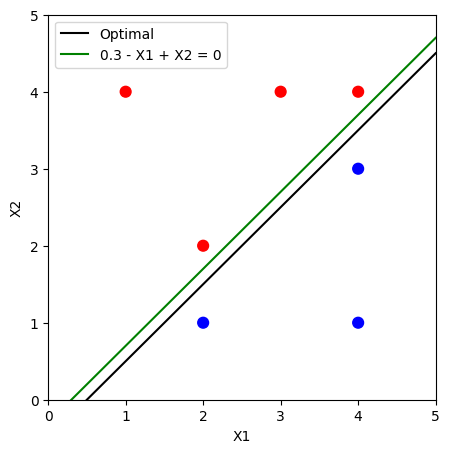

In [16]:
plot_points()
plt.plot(x, x - 0.5, "k-", label="Optimal")
plt.plot(x, x - 0.3, "g-", label="0.3 - X1 + X2 = 0")
plt.legend()
plt.show()

The green line $0.3 - X_1 + X_2 = 0$ still separates the two classes, but it's closer to the red points, so its margin is smaller and it's not optimal.

### (h)

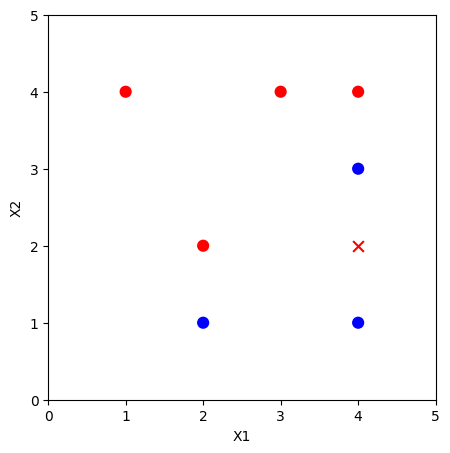

In [17]:
plot_points()
plt.scatter(4, 2, c="red", s=60, marker="x")
plt.show()

I added a red point at (4,2). It lies right between the blue points (4,1) and (4,3), so no straight line can separate the two classes anymore.